In [4]:
import requests
import pandas as pd
from pathlib import Path

BASE = "https://api.ukhsa-dashboard.data.gov.uk"

def get_amr_metric(topic, metric, geography_type="UKHSA Region", page_size=365):
    geo_url = (
        f"{BASE}/themes/infectious_disease/sub_themes/antimicrobial_resistance"
        f"/topics/{topic}/geography_types/{geography_type}/geographies?format=json"
    )
    geos = [g["name"] for g in requests.get(geo_url).json()]

    frames = []
    for geo in geos:
        url = (
            f"{BASE}/themes/infectious_disease/sub_themes/antimicrobial_resistance"
            f"/topics/{topic}/geography_types/{geography_type}"
            f"/geographies/{geo}/metrics/{metric}"
            f"?format=json&page_size={page_size}"
        )
        results = []
        while url:
            r = requests.get(url)
            r.raise_for_status()
            data = r.json()
            results.extend(data.get("results", []))
            url = data.get("next")

        if not results:
            continue

        df = pd.DataFrame(results)
        df = df.rename(columns={
            "date": "date",
            "geography": "region",
            "metric_value": "resistance",
            "stratum": "resistance_type",
            "topic": "bacteria"
        })
        keep = ["date", "region", "resistance", "bacteria", "resistance_type"]
        df = df[[c for c in keep if c in df.columns]].copy()
        df["bacteria"] = df["bacteria"].str.replace("-", "_")
        frames.append(df)

    if not frames:
        return pd.DataFrame(columns=["date", "region", "resistance", "bacteria", "resistance_type"])
    return pd.concat(frames, ignore_index=True)


# ========== CONFIG ==========
CONFIG = [
    {"topic": "E-coli", "metric": "e-coli_testing_bacteraemiaPercentResistantRollingMonth", "label": "E_coli"},
    {"topic": "E-faecalis", "metric": "e-faecalis_testing_bacteraemiaPercentResistantRollingMonth", "label": "E_faecalis"},
    {"topic": "E-faecium", "metric": "e-faecium_testing_bacteraemiaPercentResistantRollingMonth", "label": "E_faecium"},
    {"topic": "K-pneumoniae", "metric": "k-pneumoniae_testing_bacteraemiaPercentResistantRollingMonth", "label": "K_pneumoniae"},
    {"topic": "P-aeruginosa", "metric": "p-aeruginosa_testing_bacteraemiaPercentResistantRollingMonth", "label": "P_aeruginosa"},
    {"topic": "S-pneumoniae", "metric": "s-pneumoniae_testing_bacteraemiaPercentResistantRollingMonth", "label": "S_pneumoniae"},
]

# ========== DOWNLOAD ==========
all_dfs = []

for cfg in CONFIG:
    print(f"Downloading {cfg['label']} ...")
    df = get_amr_metric(
        topic=cfg["topic"],
        metric=cfg["metric"],
        geography_type="UKHSA Region"
    )
    df["bacteria"] = cfg["label"]
    print(f"  → {len(df):,} rows")
    all_dfs.append(df)

# Combine
combined_amr = pd.concat(all_dfs, ignore_index=True)
combined_amr["date"] = pd.to_datetime(combined_amr["date"])
combined_amr = combined_amr.sort_values(["bacteria", "region", "date"])

# Save
Path("data/processed").mkdir(parents=True, exist_ok=True)
combined_amr.to_csv("data/processed/amr_all_bacteria.csv", index=False)

print("\n" + "="*50)
print("FINISHED")
print(f"Total rows: {len(combined_amr):,}")
print("Bacteria:", combined_amr["bacteria"].unique().tolist())
print("Saved → data/processed/amr_all_bacteria.csv")
print("="*50)

display(combined_amr.head(10))

  → 4,788 rows
  → 684 rows
  → 684 rows
  → 4,787 rows
  → 3,951 rows
  → 1,362 rows

FINISHED
Total rows: 16,256
Bacteria: ['E_coli', 'E_faecalis', 'E_faecium', 'K_pneumoniae', 'P_aeruginosa', 'S_pneumoniae']
Saved → data/processed/amr_all_bacteria.csv


,date,region,resistance,bacteria,resistance_type
0,2020-04-01,East Midlands,0.00,E_coli,Carbapenems
1,2020-04-01,East Midlands,7.62,E_coli,Gentamicin
2,2020-04-01,East Midlands,13.19,E_coli,Third Generation Cephalosporins
3,2020-04-01,East Midlands,7.98,E_coli,Piperacillin with tazobactam
4,2020-04-01,East Midlands,45.49,E_coli,Co-amoxiclav
5,2020-04-01,East Midlands,0.49,E_coli,Amikacin
6,2020-04-01,East Midlands,18.71,E_coli,Ciprofloxacin
7,2020-05-01,East Midlands,12.05,E_coli,Third Generation Cephalosporins
8,2020-05-01,East Midlands,44.51,E_coli,Co-amoxiclav
9,2020-05-01,East Midlands,0.00,E_coli,Carbapenems


In [5]:
print("Shape:", combined_amr.shape)
print("\nBacteria counts:")
print(combined_amr["bacteria"].value_counts())

print("\nResistance types by bacteria:")
print(combined_amr.groupby("bacteria")["resistance_type"].unique())

print("\nDate range:", combined_amr["date"].min(), "→", combined_amr["date"].max())

Shape: (16256, 5)

Bacteria counts:
bacteria
E_coli          4788
K_pneumoniae    4787
P_aeruginosa    3951
S_pneumoniae    1362
E_faecalis       684
E_faecium        684
Name: count, dtype: int64

Resistance types by bacteria:
bacteria
E_coli          [Carbapenems, Gentamicin, Third Generation Cep...
E_faecalis                                        [Glycopeptides]
E_faecium                                         [Glycopeptides]
K_pneumoniae    [Carbapenems, Gentamicin, Third Generation Cep...
P_aeruginosa    [Piperacillin with tazobactam, Ciprofloxacin, ...
S_pneumoniae                             [Penicillin, Macrolides]
Name: resistance_type, dtype: object

Date range: 2020-04-01 00:00:00 → 2026-07-01 00:00:00


In [7]:
# Re-download the ones that are missing
missing = ["E_faecalis", "E_faecium", "K_pneumoniae", "P_aeruginosa", "S_pneumoniae"]

for cfg in CONFIG:
    if cfg["label"] not in combined_amr["bacteria"].unique():
        print(f"Downloading missing: {cfg['label']} ...")
        df = get_amr_metric(
            topic=cfg["topic"],
            metric=cfg["metric"],
            geography_type="UKHSA Region"
        )
        df["bacteria"] = cfg["label"]
        print(f"  → {len(df):,} rows")
        combined_amr = pd.concat([combined_amr, df], ignore_index=True)

# Clean and save again
combined_amr["date"] = pd.to_datetime(combined_amr["date"])
combined_amr = combined_amr.sort_values(["bacteria", "region", "date"])

combined_amr.to_csv("data/processed/amr_all_bacteria.csv", index=False)

print("\nUpdated bacteria counts:")
print(combined_amr["bacteria"].value_counts())


Updated bacteria counts:
bacteria
E_coli          4788
K_pneumoniae    4787
P_aeruginosa    3951
S_pneumoniae    1362
E_faecalis       684
E_faecium        684
Name: count, dtype: int64


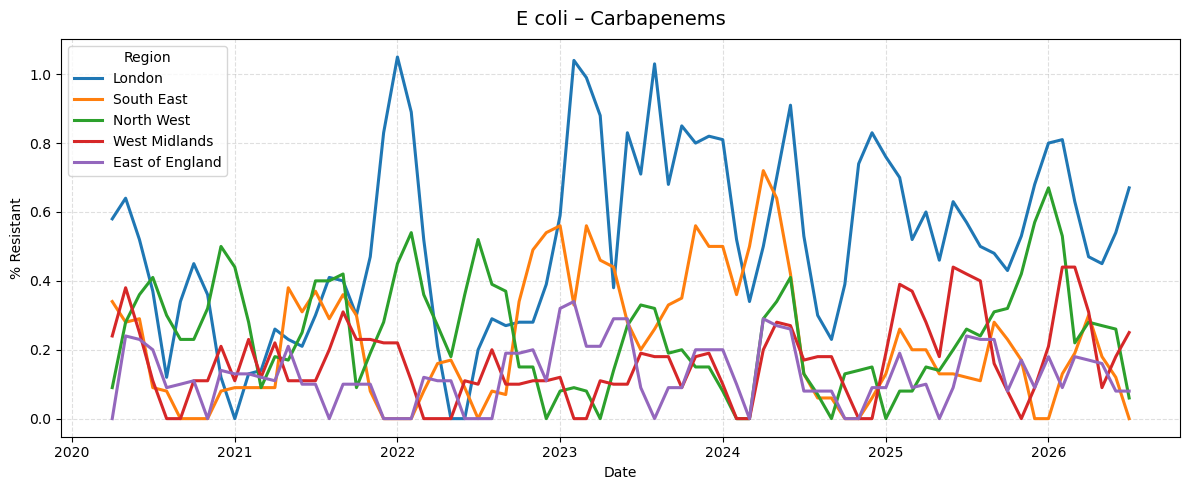

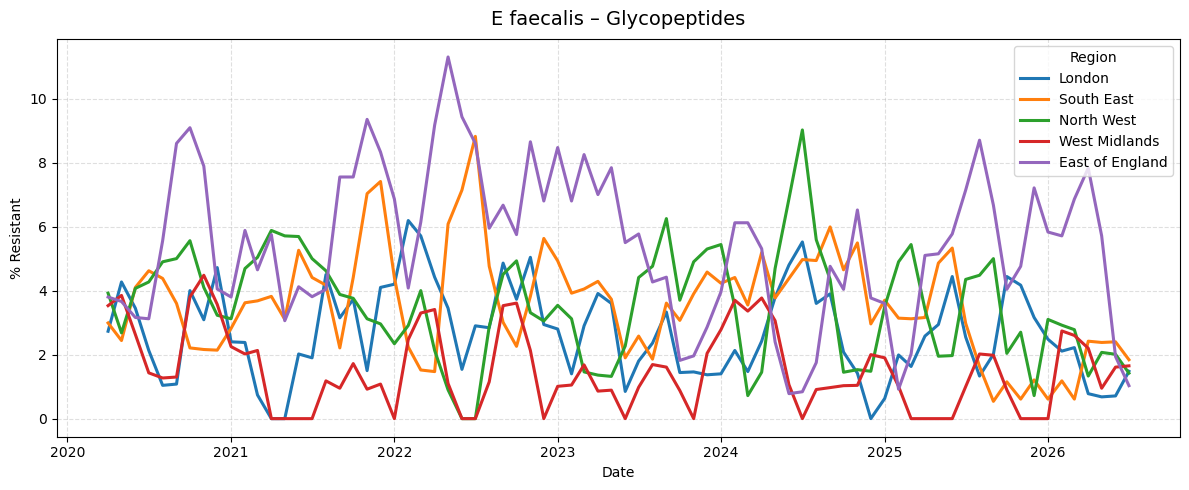

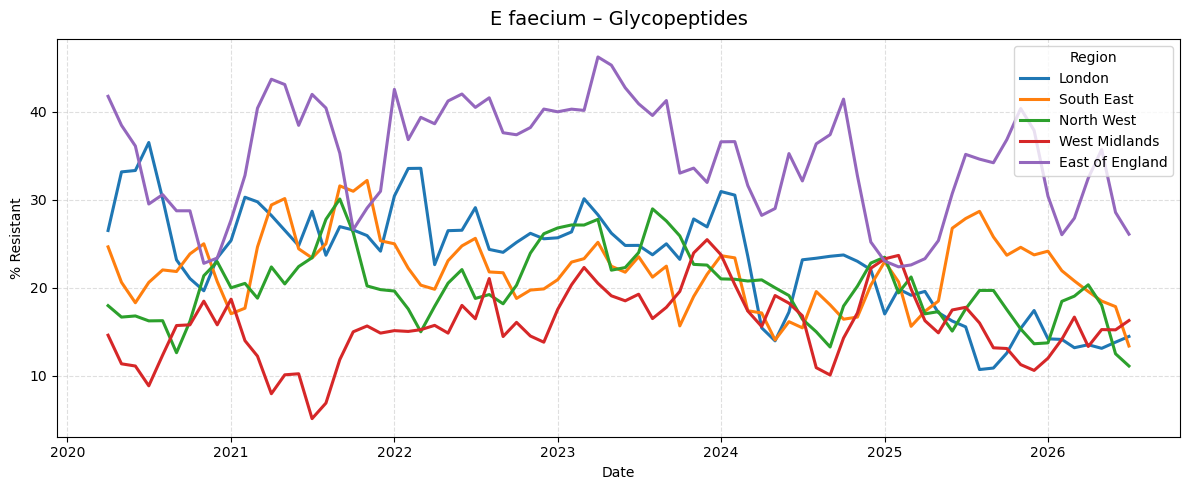

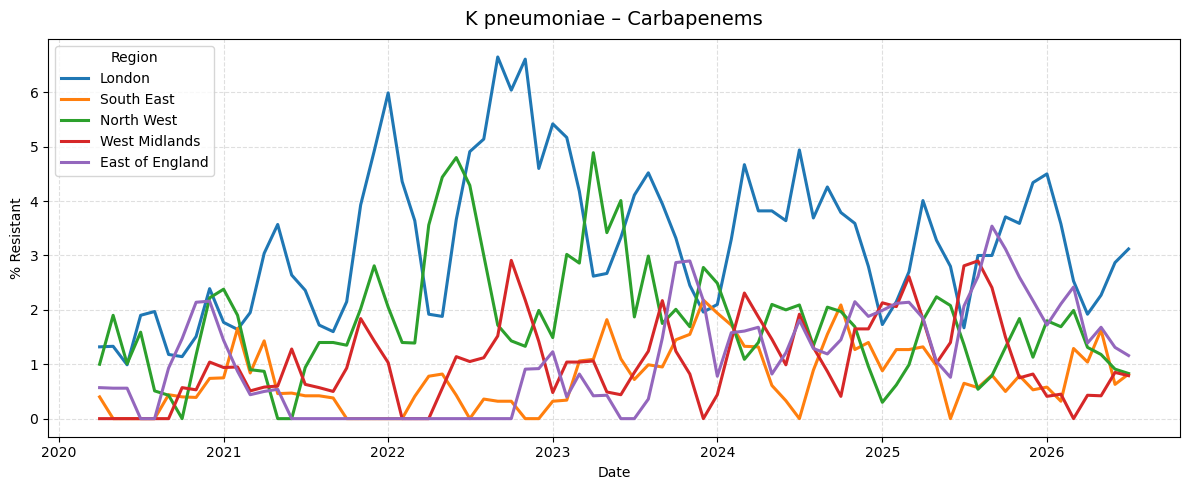

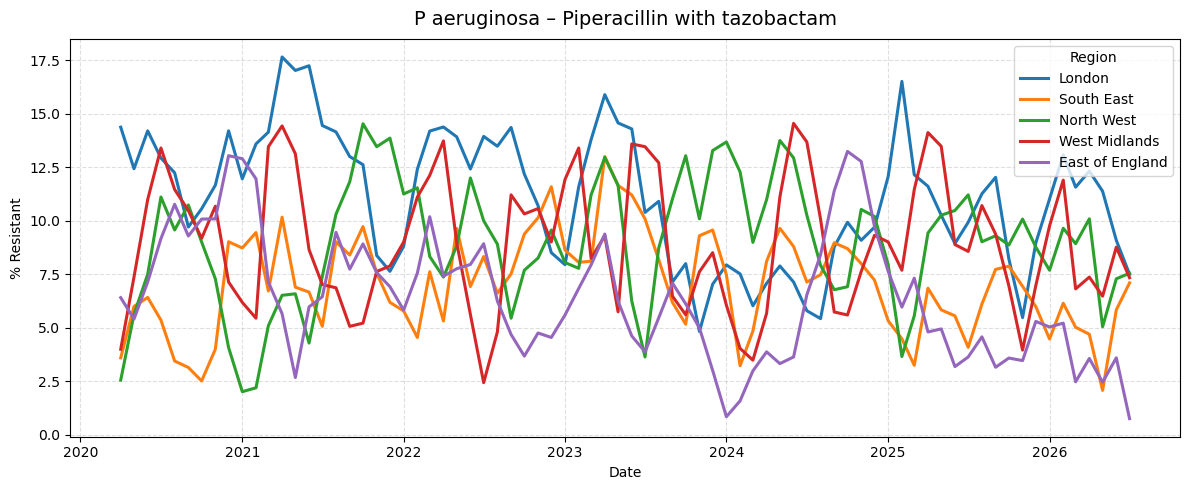

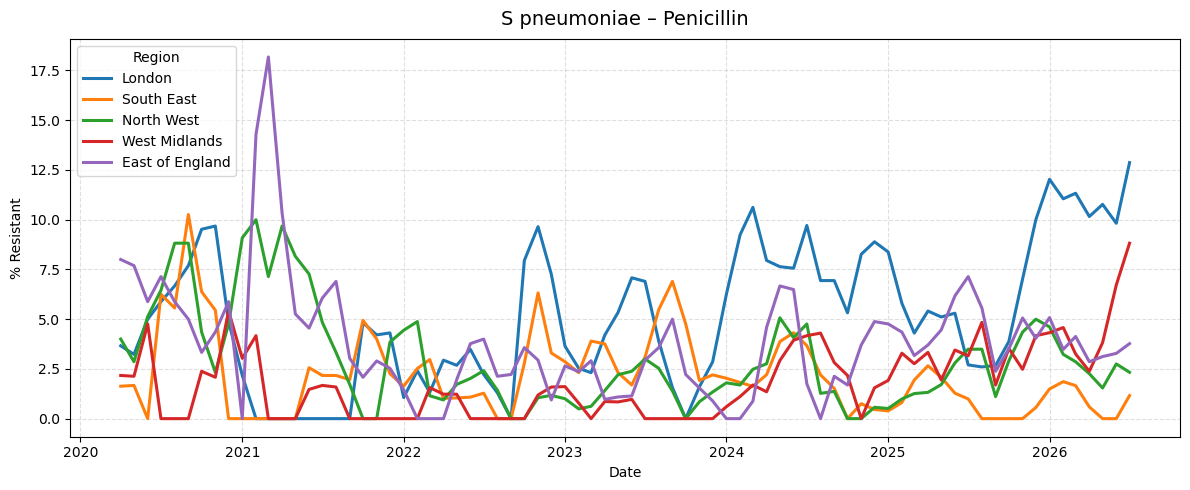

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

combined_amr["date"] = pd.to_datetime(combined_amr["date"])

# Choose only 5 main regions to keep the plot clean
main_regions = ["London", "South East", "North West", "West Midlands", "East of England"]

for bacteria in sorted(combined_amr["bacteria"].unique()):
    
    df = combined_amr[combined_amr["bacteria"] == bacteria].copy()
    
    # Take the most common resistance type
    main_resistance = df["resistance_type"].value_counts().idxmax()
    df = df[df["resistance_type"] == main_resistance]
    
    plt.figure(figsize=(12, 5))
    
    for region in main_regions:
        subset = df[df["region"] == region].sort_values("date")
        if not subset.empty:
            plt.plot(subset["date"], subset["resistance"], label=region, linewidth=2.2)
    
    plt.title(f"{bacteria.replace('_', ' ')} – {main_resistance}", fontsize=14, pad=10)
    plt.xlabel("Date")
    plt.ylabel("% Resistant")
    
    # Clean date formatting
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    plt.gca().xaxis.set_major_locator(mdates.YearLocator())
    plt.xticks(rotation=0)
    
    plt.legend(title="Region")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

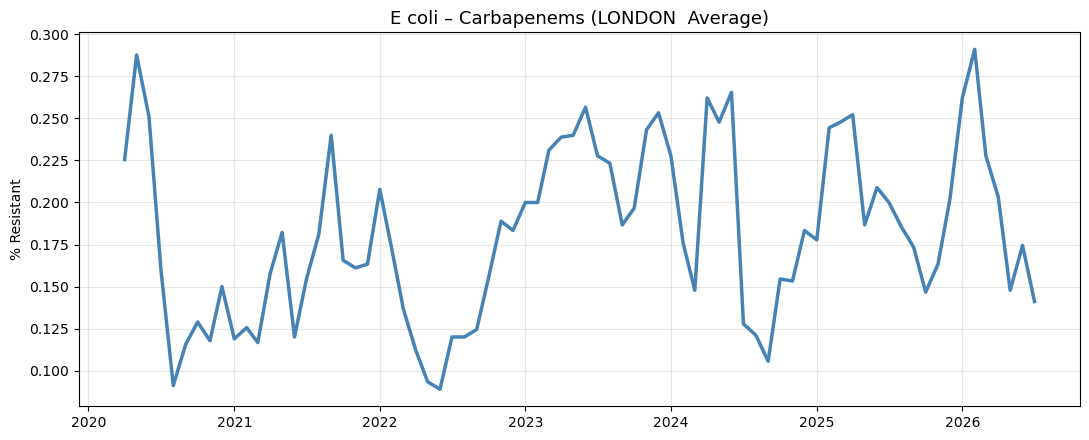

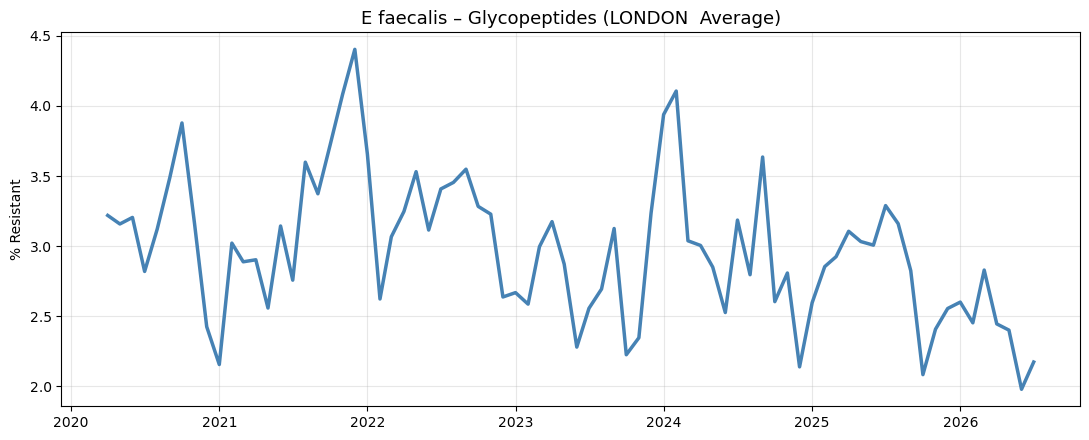

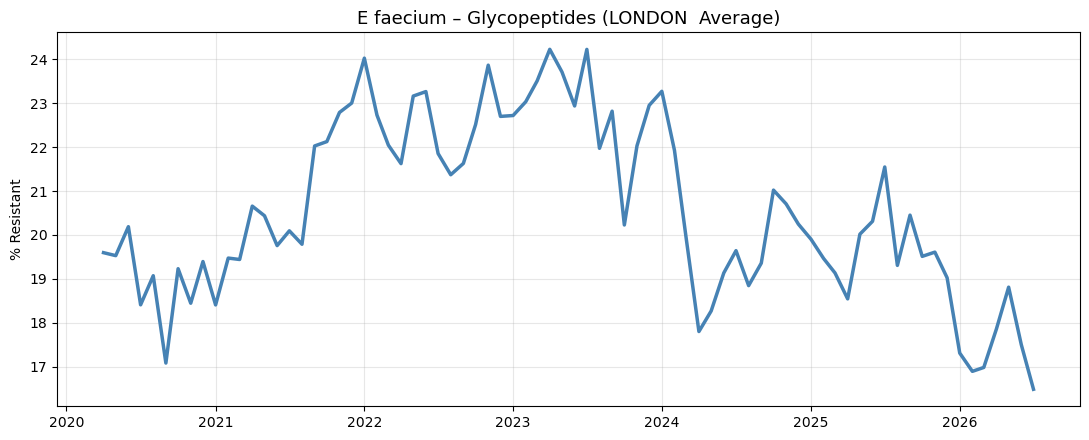

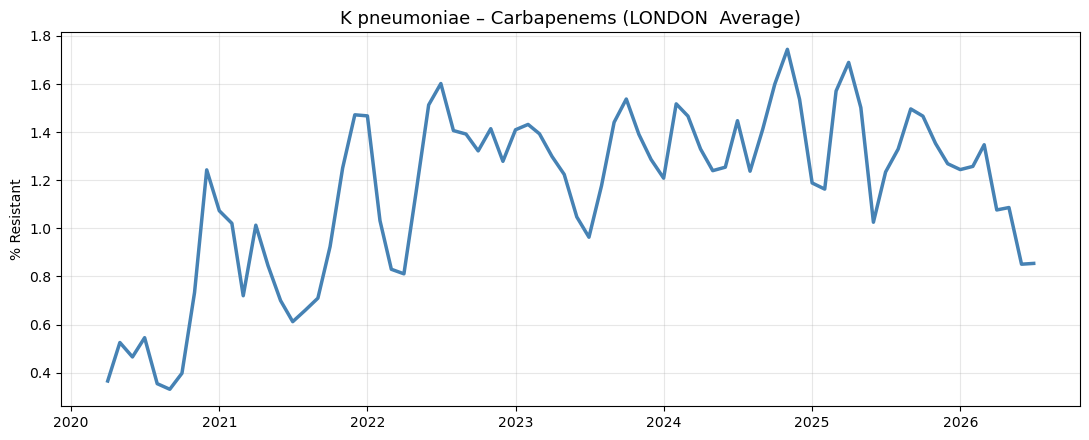

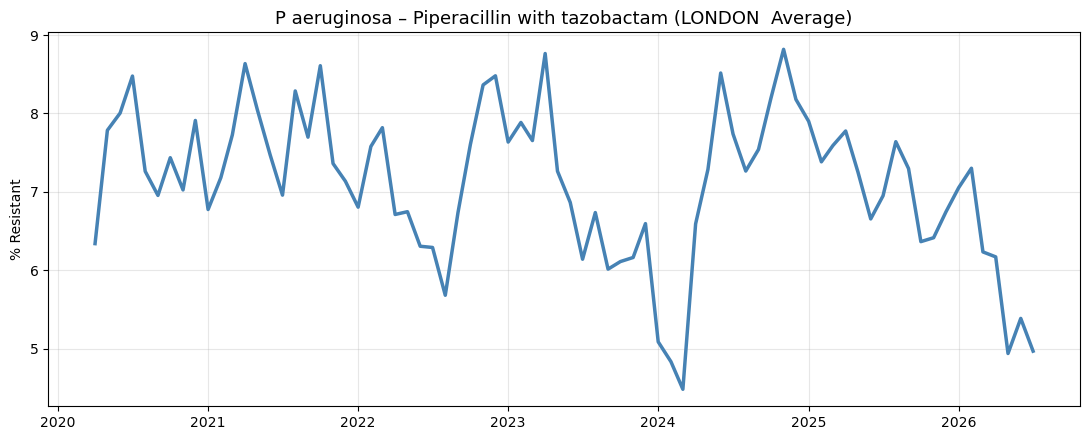

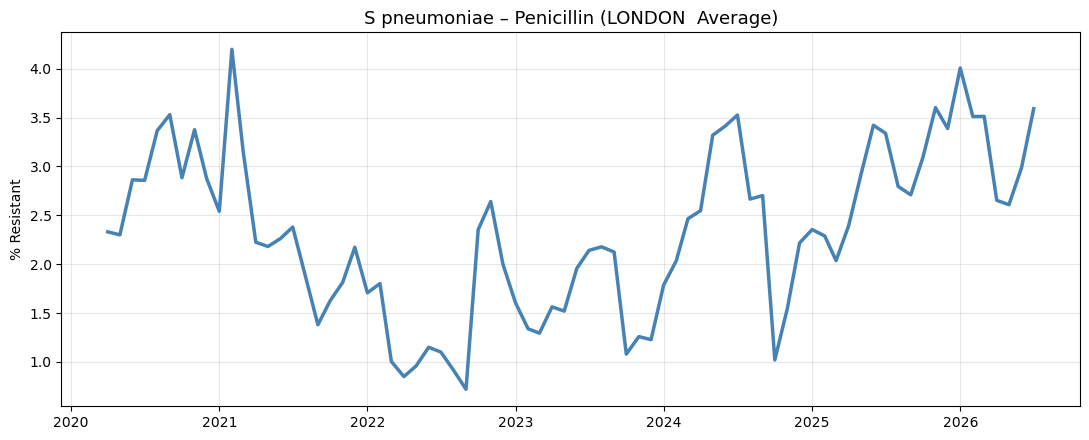

In [12]:
for bacteria in sorted(combined_amr["bacteria"].unique()):
    
    df = combined_amr[combined_amr["bacteria"] == bacteria]
    main_resistance = df["resistance_type"].value_counts().idxmax()
    
    # Calculate average across all regions
    avg = (df[df["resistance_type"] == main_resistance]
           .groupby("date")["resistance"]
           .mean()
           .reset_index())
    
    plt.figure(figsize=(11, 4.5))
    plt.plot(avg["date"], avg["resistance"], color="steelblue", linewidth=2.5)
    
    plt.title(f"{bacteria.replace('_', ' ')} – {main_resistance} (LONDON  Average)", fontsize=13)
    plt.ylabel("% Resistant")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()